### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [7]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [8]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [9]:
data.shape

(31972, 14)

In [10]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

Only rice has Quality. That is why null row of Quality is 25706.

### Prepare for Prediction

In [11]:
DAFY = data.copy()
DAFY = DAFY[['date', 'price']]
DAFY['date'] = pd.to_datetime(DAFY['date'])
mask = (DAFY['date']>=obv_st_date) & (DAFY['date']<=obv_end_date)
DAFY = DAFY.loc[mask]

In [12]:
DAFY = DAFY.set_index('date')
DAFY.tail()

,price
date,
2022-01-15,347.0
2022-01-15,3325.0
2022-01-15,2040.0
2022-01-15,755.0
2022-01-15,1833.0


In [13]:
DAFY = DAFY.resample('AS-JAN').mean()
DAFY.head()

,price
date,
2008-01-01,1002.766567
2009-01-01,805.337847
2010-01-01,900.166229
2011-01-01,972.709289
2012-01-01,832.871728


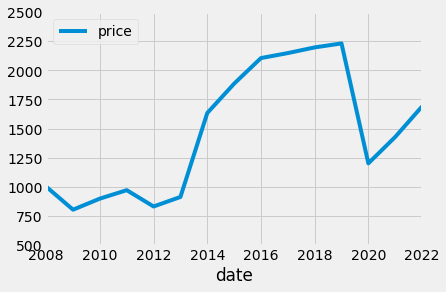

In [14]:
DAFY.plot(grid=True)
plt.show()

##### Checking Random Walk

In [15]:
RW_DAFY = adfuller(DAFY['price'])
RW_DAFY[1] # print P-value. If p-value<5%, reject null hypothesis

0.6041340590823863

##### Plot ACF and PACF

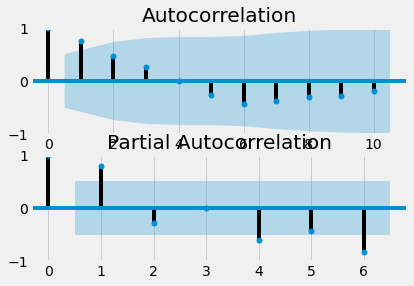

In [16]:
fig, axes=plt.subplots(2,1)
plot_acf(DAFY, lags=10, ax=axes[0])
plot_pacf(DAFY, lags=6, ax=axes[1])
plt.show()

##### Choose smallest AIC and BIC

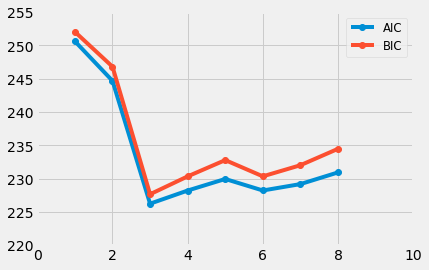

In [17]:
AIC, BIC = AIC_BIC_withOrderRange(DAFY, p=3, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(1,0,0), 4:(1,0,1), 5:(1,0,2), 6:(2,0,0), 7:(2,0,1), 8:(2,0,2)

In [18]:
AIC, BIC

(array([265.08155635, 250.60946577, 244.67489989, 226.24448194,
        228.21635734, 229.95001795, 228.22354335, 229.18240803,
        230.93439575]),
 array([265.78960655, 252.02556617, 246.79905049, 227.66058234,
        230.34050794, 232.78221876, 230.34769395, 232.01460883,
        234.47464676]))

We shouldn't choose the AIC or BIC with values `0.`

##### We will run (0,0,1), #1 (1,0,0), #2 (1,0,1), #3 (2,0,0), #4 (2,0,0) #6

In [19]:
mod_orders = [
    (0,0,1), #1
    (1,0,0), #2
    (1,0,1), #3
    (2,0,0), #4
    (2,0,0) #6
]

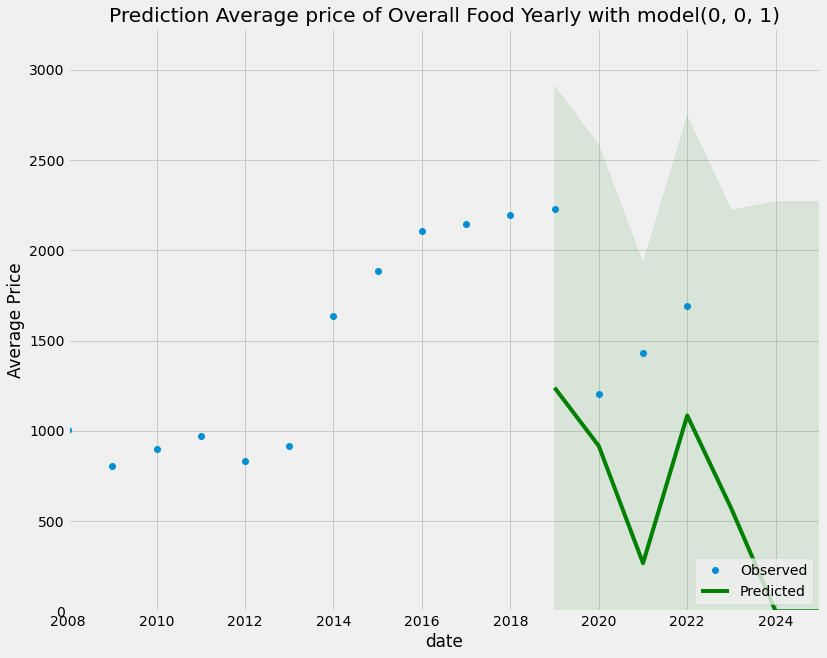

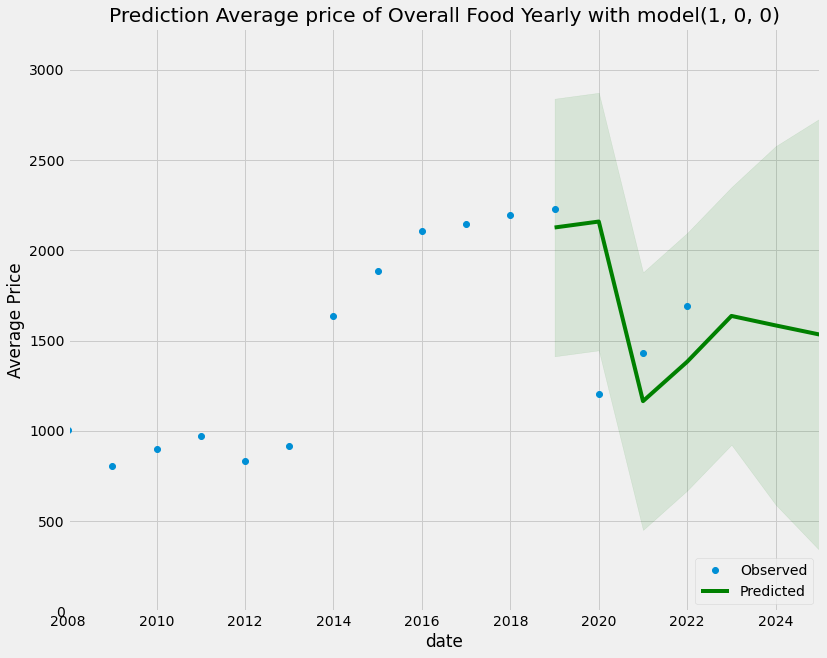

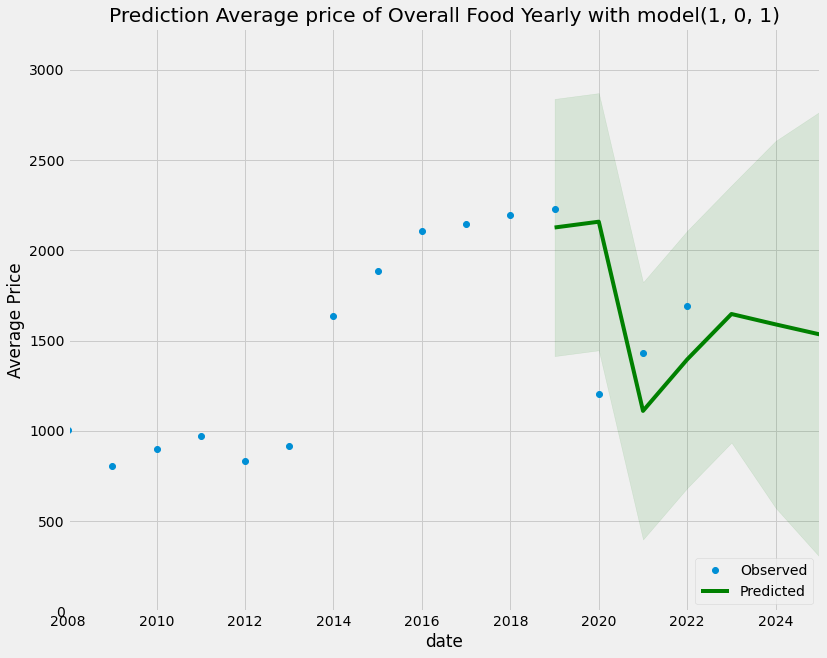

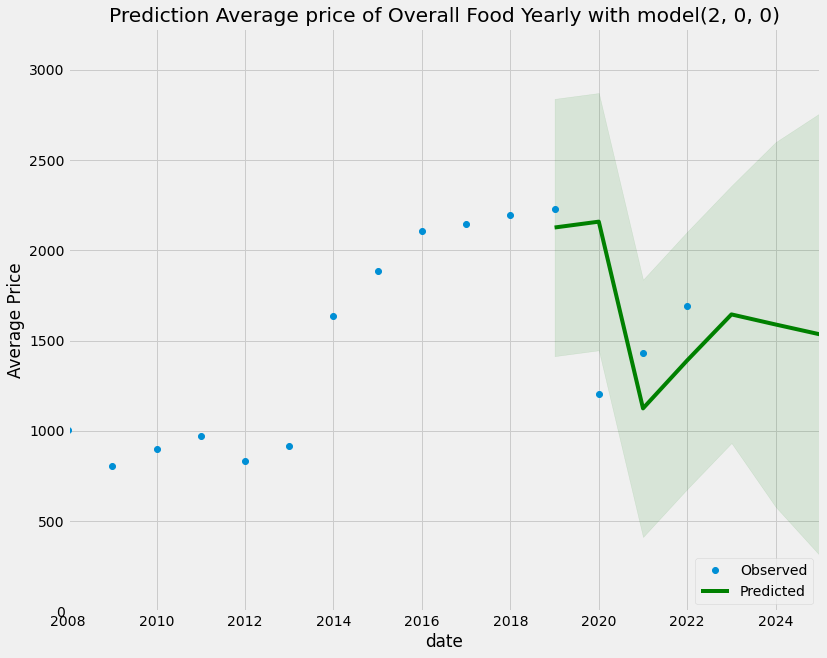

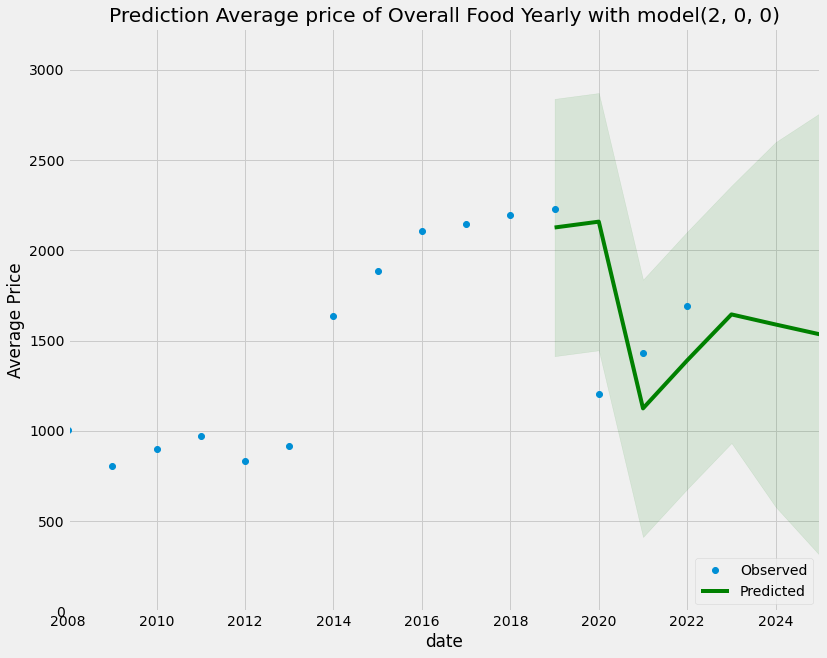

In [23]:
DAFY_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DAFY, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Overall Food Yearly with model'+str(order), xlabel='Year', ylabel='Average Price')
    DAFY_models.append(model)

Most of Models aren't different very much. We should choose the model with less parameter. So, choose AR1 (1, 0, 0) Model that is also with less error in AIC, BIC

In [21]:
DAFY_model = DAFY_models[1]

In [22]:
DAFY_pred = DAFY_model.predict(pred_st_date, pred_end_date)
DAFY_pred

2019-01-01    2126.082230
2020-01-01    2159.076055
2021-01-01    1164.087260
2022-01-01    1382.795999
2023-01-01    1636.209085
2024-01-01    1583.678107
2025-01-01    1532.833651
Freq: AS-JAN, Name: predicted_mean, dtype: float64